(course-antiviral-geometric-transformations)=

# Path C - Module 46: Geometric Transformations (Space)

Use an explicit moving population and a captured center to understand rigid coordinate rotations while keeping the other atoms fixed. The example is a geometric exercise, not a prediction of a new bound pose.

(course-antiviral-geometric-transformations-moving-population)=
## 1. Choosing the inhibitor chain

The N3 inhibitor in 6LU7 is deposited as a peptide-like chain spanning six
groups, including 02J, PJE and 010. Select its author chain name C explicitly;
in the mmCIF input used by the PDB-ID route, its label chain ID is B. Neither
label is an atom index. A generic small-molecule classification does not select
this whole inhibitor, and there is no single group named N3.

The deposited inhibitor has a covalent connection to the protein. This rigid
coordinate exercise does not establish a physically valid reoriented pose or
change chemical assignments. The checks below verify the requested geometry
and leave every atom outside the chosen population fixed.


Rotated 49 atoms from author chain C.


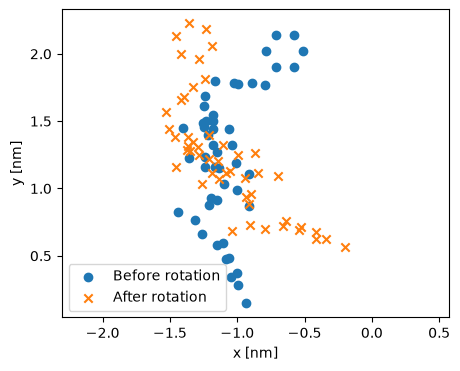

In [1]:
import molsysmt as msm
import numpy as np
import matplotlib.pyplot as plt

puw = msm.pyunitwizard
molsys = msm.convert('pdb:6LU7', to_form='molsysmt.MolSys')
inhibitor_atom_indices = msm.select(molsys, selection='chain_name=="C"')
assert inhibitor_atom_indices, "The deposited inhibitor chain must be present."
before_rotation = puw.get_value(msm.get(molsys, coordinates=True), to_unit='nm').copy()
angle = np.deg2rad(45.0)
rotation = np.array([[np.cos(angle), -np.sin(angle), 0.0],
                     [np.sin(angle), np.cos(angle), 0.0],
                     [0.0, 0.0, 1.0]])
rotation_center = msm.structure.get_center(molsys, selection=inhibitor_atom_indices)
msm.structure.rotate(molsys, selection=inhibitor_atom_indices, rotation=rotation,
                     rotation_center=rotation_center, in_place=True)
after_rotation = puw.get_value(msm.get(molsys, coordinates=True), to_unit='nm')
center_nm = puw.get_value(rotation_center, to_unit='nm')
expected = ((before_rotation[:, inhibitor_atom_indices] - center_nm)
            @ rotation.T + center_nm)
np.testing.assert_allclose(after_rotation[:, inhibitor_atom_indices], expected,
                           rtol=0, atol=1e-12)
untouched = np.ones(before_rotation.shape[1], dtype=bool)
untouched[inhibitor_atom_indices] = False
np.testing.assert_array_equal(after_rotation[:, untouched], before_rotation[:, untouched])
print(f"Rotated {len(inhibitor_atom_indices)} atoms from author chain C.")

plt.figure(figsize=(5, 4))
plt.scatter(before_rotation[0, inhibitor_atom_indices, 0],
            before_rotation[0, inhibitor_atom_indices, 1], label='Before rotation')
plt.scatter(after_rotation[0, inhibitor_atom_indices, 0],
            after_rotation[0, inhibitor_atom_indices, 1], label='After rotation', marker='x')
plt.xlabel('x [nm]')
plt.ylabel('y [nm]')
plt.axis('equal')
plt.legend()
plt.show()


(course-antiviral-geometric-transformations-axis-angle)=
## 2. Constructing the rotation

You can describe the inhibitor's positive 45-degree z rotation with an axis and an
explicit angle instead of writing its matrix by hand. The axis is unit-free;
the angle must carry degree or radian units. This checks the same matrix already
used above, without applying another rotation to your molecular pose.


In [2]:
rotation_from_axis_angle = msm.structure.get_rotation_matrix_from_axis_angle(
    axis=[0, 0, 1], angle='45 degrees')
np.testing.assert_allclose(
    rotation_from_axis_angle, rotation, rtol=0, atol=1e-12)


(course-antiviral-geometric-transformations-axis-angle-links)=
:::{seealso}
:class: dropdown

See the {ref}`axis-angle example <Tutorial_Rotate_axis_angle>` for input units,
source preservation and the active rotation convention, and
{func}`molsysmt.structure.get_rotation_matrix_from_axis_angle` for its contract.
:::


Raw XYZ coordinate quantities may have shape `(3,)`, `(n_atoms, 3)` or `(n_structures, n_atoms, 3)`. Rotation and translation preserve this storage shape, its unit and its quantity library. Independent results promote integer storage to float64; existing floating dtype is kept. Use floating storage for in-place edits: floating updates to integer XYZ reject before any write rather than discard fractions. Ordinary copying preserves the original dtype.
